# Exercise 1

#### Students Name and ID:
- Gal Noy 209346485
- Amit Ezer 316097575


Run from top to bottom with the four CSV files beside the notebook.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(precision=6, suppress=True)


## Question 1

### (a–b) Signal 1: DFT

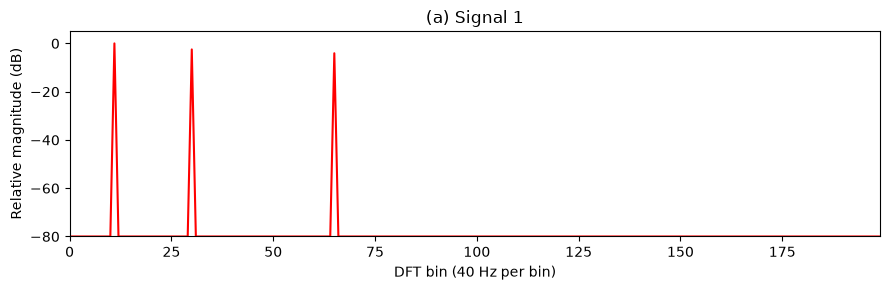

In [40]:
N = 400
sample_rate = 16_000
amplitudes = [0.4, 0.3, 0.25]
phases = [np.pi / 4, 0, -3 * np.pi / 4]
frequencies_1 = [440, 1200, 2600]

t = np.arange(N) / sample_rate


def make_signal(frequencies):
    return sum(
        amplitude * np.cos(2 * np.pi * frequency * t + phase)
        for amplitude, frequency, phase in zip(amplitudes, frequencies, phases)
    )


# W[k, n] = exp(-2πikn/N)
k = np.arange(N)[:, None]
n = np.arange(N)[None, :]
W = np.exp(-2j * np.pi * k * n / N)


def plot_spectrum(spectrum, title, windowed=None):
    peak = np.max(np.abs(spectrum[: N // 2]))

    def db(values):
        magnitude = np.abs(values[: N // 2]) / peak
        return 20 * np.log10(np.maximum(magnitude, 1e-4))

    plt.figure(figsize=(9, 3))
    plt.plot(db(spectrum), 'r', label='Original' if windowed is not None else None)
    if windowed is not None:
        plt.plot(db(windowed), 'g', label='Hamming')
        plt.legend()
    plt.title(title)
    plt.xlabel('DFT bin (40 Hz per bin)')
    plt.ylabel('Relative magnitude (dB)')
    plt.ylim(-80, 5)
    plt.xlim(0, N // 2 - 1)
    plt.tight_layout()
    plt.show()


signal_1 = make_signal(frequencies_1)
X1 = W @ signal_1
plot_spectrum(X1, '(a) Signal 1')


### (c) Signal 1: amplitude and phase

$A = 2|X[k]|/N$, $\phi = \arg(X[k])$.

In [41]:
bin_width = sample_rate / N

def print_tones(frequencies, spectrum):
    print(f"{'Tone (Hz)':>10} {'Bin':>5} {'Amplitude':>12} {'Phase (rad)':>13}")
    for frequency in frequencies:
        position = frequency / bin_width
        lower = int(np.floor(position))
        bins = [lower, lower + 1] if position - lower == 0.5 else [int(position + 0.5)]
        for k in bins:
            amplitude = 2 * np.abs(spectrum[k]) / N
            phase = np.angle(spectrum[k])
            print(f'{frequency:10} {k:5} {amplitude:12.5f} {phase:13.5f}')


print_tones(frequencies_1, X1)


 Tone (Hz)   Bin    Amplitude   Phase (rad)
       440    11      0.40000       0.78540
      1200    30      0.30000       0.00000
      2600    65      0.25000      -2.35619


### (d) Signal 2: DFT

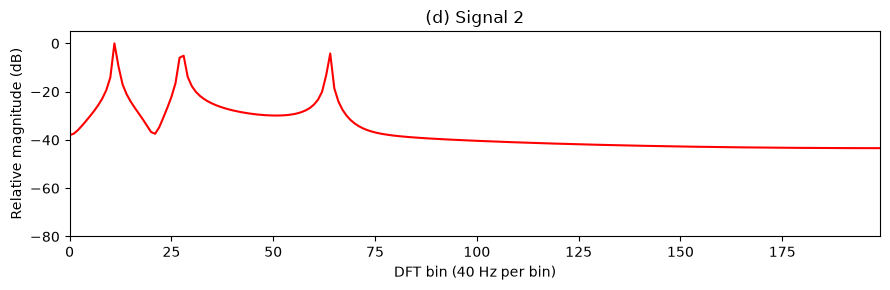

In [42]:
frequencies_2 = [450, 1100, 2550]
signal_2 = make_signal(frequencies_2)
X2 = W @ signal_2
plot_spectrum(X2, '(d) Signal 2')


### (e) Signal 2: amplitude and phase

In [43]:
print_tones(frequencies_2, X2)


 Tone (Hz)   Bin    Amplitude   Phase (rad)
       450    11      0.35950       1.55805
      1100    27      0.18144       1.54371
      1100    28      0.20022      -1.54607
      2550    64      0.22197      -3.11427


### (f) Hamming window

$w[n] = \frac{25}{54} - \frac{21}{54}\cos(2\pi n/N)$.

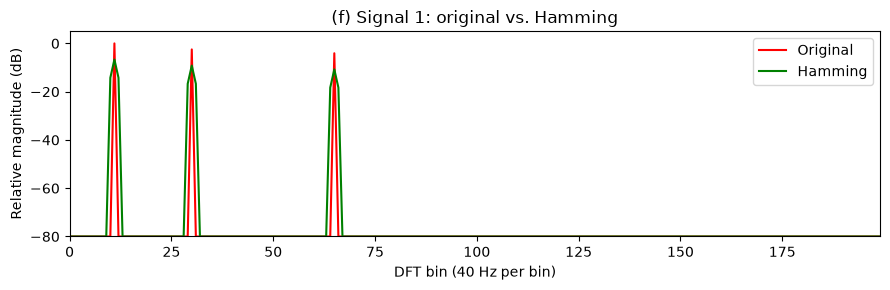

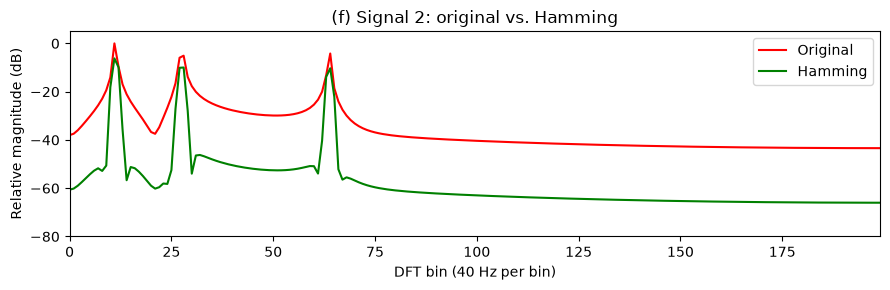

In [44]:
window = 25 / 54 - 21 / 54 * np.cos(2 * np.pi * np.arange(N) / N)
X1_windowed = W @ (signal_1 * window)
X2_windowed = W @ (signal_2 * window)

plot_spectrum(X1, '(f) Signal 1: original vs. Hamming', X1_windowed)
plot_spectrum(X2, '(f) Signal 2: original vs. Hamming', X2_windowed)


### (g) Windowed tone coefficients

In [45]:
print('Signal 1 (windowed)')
print_tones(frequencies_1, X1_windowed)
print('\nSignal 2 (windowed)')
print_tones(frequencies_2, X2_windowed)


Signal 1 (windowed)
 Tone (Hz)   Bin    Amplitude   Phase (rad)
       440    11      0.18519       0.78540
      1200    30      0.13889       0.00000
      2600    65      0.11574      -2.35619

Signal 2 (windowed)
 Tone (Hz)   Bin    Amplitude   Phase (rad)
       450    11      0.17601       1.56887
      1100    27      0.11248       1.56756
      1100    28      0.11385      -1.56758
      2550    64      0.10980      -3.13751


## Question 2

### Gaussian class

In [46]:
class Gaussian:
    def __init__(self, mean, covariance):
        self.mean = np.asarray(mean)
        self.covariance = np.asarray(covariance)
        self.diagonal = self.covariance.ndim == 1

        if self.diagonal:
            self.inverse_covariance = 1 / self.covariance
            log_det = np.log(self.covariance).sum()
        else:
            self.inverse_covariance = np.linalg.inv(self.covariance)
            log_det = np.linalg.slogdet(self.covariance)[1]

        d = len(self.mean)
        self.log_normalization = -0.5 * (d * np.log(2 * np.pi) + log_det)
        self.normalization_constant = np.exp(self.log_normalization)

    def log_likelihood(self, x):
        diff = x - self.mean
        if self.diagonal:
            squared_distance = np.sum(diff**2 * self.inverse_covariance)
        else:
            squared_distance = diff @ self.inverse_covariance @ diff
        return self.log_normalization - 0.5 * squared_distance


### Gaussian estimators

In [47]:
def build_diagonal_covariance_gaussian(filename):
    data = np.loadtxt(filename, delimiter=',')
    mean = data.mean(axis=0)
    variances = np.mean((data - mean) ** 2, axis=0)
    return Gaussian(mean, variances)


def build_full_covariance_gaussian(filename):
    data = np.loadtxt(filename, delimiter=',')
    mean = data.mean(axis=0)
    centered = data - mean
    covariance = centered.T @ centered / len(data)
    return Gaussian(mean, covariance)


### (a) Build Gaussians from `data_1.csv`

In [48]:
np.set_printoptions(precision=6, suppress=True)

def print_parameters(name, model):
    print(f'{name}:')
    print('Mean:', model.mean)
    print('Covariance:', model.covariance)
    print('Normalization constant:', model.normalization_constant)

gaussian_1_diagonal = build_diagonal_covariance_gaussian('data_1.csv')
gaussian_1_full = build_full_covariance_gaussian('data_1.csv')
print_parameters('Diagonal Gaussian', gaussian_1_diagonal)
print_parameters('Full Gaussian', gaussian_1_full)


Diagonal Gaussian:
Mean: [-0.098231 -0.097654  0.084253]
Covariance: [11.300731  1.480702  6.454034]
Normalization constant: 0.006109806837349655
Full Gaussian:
Mean: [-0.098231 -0.097654  0.084253]
Covariance: [[11.300731 -0.032292  0.25859 ]
 [-0.032292  1.480702 -0.079734]
 [ 0.25859  -0.079734  6.454034]]
Normalization constant: 0.0061147987755828135


### (b) Evaluate `query_1.csv`

In [49]:
def print_likelihoods(queries, diagonal, full):
    print(f"{'Query':>5} {'Diagonal':>12} {'Full':>12}")
    for i, x in enumerate(queries, start=1):
        print(f'{i:5} {diagonal.log_likelihood(x):12.6f} {full.log_likelihood(x):12.6f}')

queries_1 = np.loadtxt('query_1.csv', delimiter=',')
print_likelihoods(queries_1, gaussian_1_diagonal, gaussian_1_full)


Query     Diagonal         Full
    1    -9.598437    -9.595777
    2    -6.439222    -6.397500
    3    -7.255353    -7.226701
    4    -6.604090    -6.562551
    5    -5.701920    -5.692899
    6    -5.308776    -5.309611
    7    -7.417854    -7.458339
    8    -7.273178    -7.289781
    9    -5.601006    -5.583757
   10    -7.302052    -7.275010


### (c) Build Gaussians from `data_2.csv`

In [50]:
gaussian_2_diagonal = build_diagonal_covariance_gaussian('data_2.csv')
gaussian_2_full = build_full_covariance_gaussian('data_2.csv')
print_parameters('Diagonal Gaussian', gaussian_2_diagonal)
print_parameters('Full Gaussian', gaussian_2_full)


Diagonal Gaussian:
Mean: [ 5.29858  -0.881825  1.290526]
Covariance: [8.886413 6.460199 3.886459]
Normalization constant: 0.004250763881455514
Full Gaussian:
Mean: [ 5.29858  -0.881825  1.290526]
Covariance: [[ 8.886413  3.424745  1.619543]
 [ 3.424745  6.460199 -1.892735]
 [ 1.619543 -1.892735  3.886459]]
Normalization constant: 0.0061166456449142405


### (d) Evaluate `query_2.csv`

In [51]:
queries_2 = np.loadtxt('query_2.csv', delimiter=',')
print_likelihoods(queries_2, gaussian_2_diagonal, gaussian_2_full)


Query     Diagonal         Full
    1    -8.336550    -9.595454
    2    -6.975472    -6.397200
    3    -8.348692    -7.226405
    4    -7.369369    -6.562250
    5    -5.631708    -5.692596
    6    -5.646387    -5.309307
    7    -8.762895    -7.458044
    8    -7.700626    -7.289480
    9    -5.904931    -5.583454
   10    -6.289201    -7.274711


### (e) Comparison

Discuss the effect of covariance between dimensions in the PDF report.